# ЛР 5. Градиентный бустинг

## Данные

Avila. По 10 признакам фрагмента текста предсказываем одного из 12 переписчиков. Это помогает распределять фрагменты перед ручной проверкой. Используем разбиение UCI и три стратифицированных фолда в обучающей части. [Источник](https://doi.org/10.24432/C5K02X)

Tasmania. По координатам 16 преобразователей предсказываем мощность фермы. Это позволяет отбирать конфигурации перед запуском симулятора. Мощности отдельных преобразователей исключаем, поскольку их сумма практически равна цели. Берем 7200 конфигураций. Раскладки с одинаковыми координатами после округления до 10 м попадают в одну группу. Группы разделяем между обучением и тестом. В обучающей части три групповых фолда. [Источник](https://doi.org/10.24432/C5831S)

In [1]:
import pandas as pd
from IPython.display import display
from labkit.data import load_tasks
from labkit.experiments import (
    comparison_text, describe_data, evaluate_holdout, plot_predictions,
    plot_training, primary_metric, save_scores, select_candidates,
)

LAB = 5
tasks = load_tasks()
display(describe_data(tasks))
for task in tasks:
    display(pd.Series(task.audit, name=task.title).to_frame())

,задача,строк в исходных файлах,train,test,исходные признаки,разбиение
0,Avila,20867,10430,10437,10,"Разбиение UCI, 3 стратифицированных фолда на t..."
1,Tasmania,72000,5762,1438,32,"20% групп на тесте, 3 групповых фолда на train."


,Avila
Точных совпадений векторов признаков между train/test,0


,Tasmania
Строк после проверки диапазонов и пропусков,72000
Точных уникальных конфигураций,72000
Строк в воспроизводимой подвыборке,7200
Групп в подвыборке (округление координат до 10 м),7183


## Метрики

Avila. Macro-F1 дает одинаковый вес каждому классу. Balanced accuracy усредняет полноту по классам. Accuracy показывает общую долю верных ответов.

Tasmania. MAE показывает средний промах в МВт. RMSE сильнее учитывает крупные ошибки. R² сравнивает модель с прогнозом среднего.

Для сравнения простая модель предсказывает самый частый класс или медианную мощность из обучающей выборки.

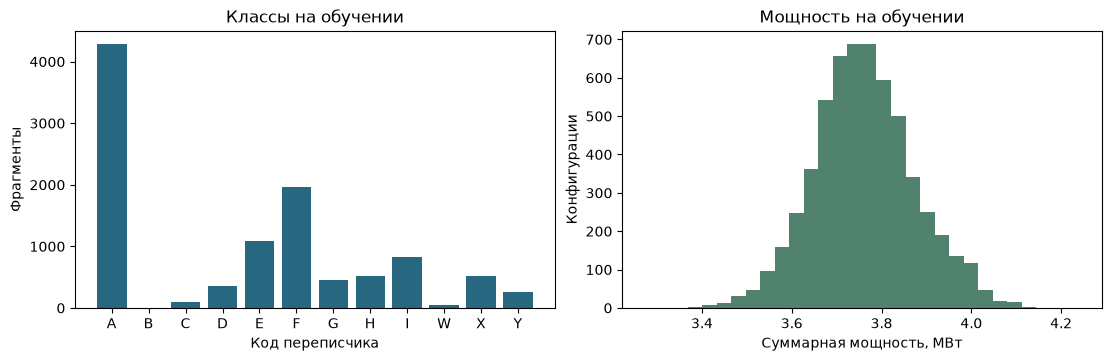

In [2]:
plot_training(tasks)

## Бейзлайн sklearn

В sklearn используем 32 итерации, глубину 2, минимум 5 объектов в листе и шаг 0,1. Для классификации используется мультиномиальная log-loss, для регрессии квадратичная ошибка.

## Подбор параметров

Проверяем глубину деревьев и число итераций. Более глубокие деревья могут находить взаимодействия признаков. В Avila также проверяем меньший шаг. В Tasmania сравниваем геометрические признаки отдельно и вместе с координатами.

Выбор по среднему macro-F1 или MAE на трех фолдах. Масштабирование обучается внутри каждого фолда. При равенстве оценок берем первый вариант.

In [3]:
selections = select_candidates(LAB, tasks)
for task in tasks:
    print(f"{task.title} ({primary_metric(task)})")
    display(selections[task.key][2].round(5))

Avila (macro_f1)


,гипотеза,признаки,настройки,CV среднее,CV std,фолд 1,фолд 2,фолд 3,выбран
0,Бейзлайн,raw,{},0.72007,0.02000,0.70127,0.71785,0.74109,False
1,Глубина 3 и 48 итераций,raw,"{""max_depth"": 3, ""n_estimators"": 48}",0.88832,0.02913,0.88295,0.86225,0.91976,False
2,Глубина 4,raw,"{""max_depth"": 4}",0.91058,0.03155,0.92028,0.87533,0.93614,True
3,Меньший шаг и 64 итерации,raw,"{""learning_rate"": 0.05, ""n_estimators"": 64}",0.75493,0.03285,0.76876,0.71743,0.77860,False


Tasmania (mae_mw)


,гипотеза,признаки,настройки,CV среднее,CV std,фолд 1,фолд 2,фолд 3,выбран
0,Бейзлайн,raw,{},0.07368,0.00087,0.07468,0.07316,0.07319,False
1,Геометрия,geometry,{},0.05900,0.00093,0.05847,0.06008,0.05846,False
2,Глубина 3 и 48 итераций,raw,"{""max_depth"": 3, ""n_estimators"": 48}",0.06312,0.00042,0.06360,0.06289,0.06287,False
3,Геометрия и глубина 3,geometry,"{""max_depth"": 3, ""n_estimators"": 48}",0.05314,0.00076,0.05296,0.05397,0.05249,False
4,"Координаты и геометрия, глубина 3",combined,"{""max_depth"": 3, ""n_estimators"": 48}",0.05168,0.00074,0.05100,0.05247,0.05156,True


## Результаты sklearn

Начальную и выбранную модели обучаем на всей обучающей выборке и проверяем на тесте.

In [4]:
results = evaluate_holdout(LAB, tasks, selections)
for task in tasks:
    table, _ = results[task.key]
    base = table.loc[table["version"].isin(["dummy", "sklearn baseline", "sklearn tuned"])]
    print(task.title)
    display(base.dropna(axis=1, how="all").drop(columns=["lab", "task", "algorithm"]).round(5))

Avila


,version,candidate,fit_s,predict_s,macro_f1,balanced_accuracy,accuracy
0,dummy,Мода,NaN,NaN,0.04852,0.08333,0.41065
1,sklearn baseline,Бейзлайн,10.36659,0.06387,0.78335,0.73829,0.75328
2,sklearn tuned,Глубина 4,20.20811,0.12893,0.92901,0.91141,0.88867


Tasmania


,version,candidate,fit_s,predict_s,mae_mw,rmse_mw,r2
0,dummy,Медиана,NaN,NaN,0.08752,0.11228,-0.00000
1,sklearn baseline,Бейзлайн,2.22370,0.00656,0.07457,0.09615,0.26670
2,sklearn tuned,"Координаты и геометрия, глубина 3",7.63791,0.11807,0.05014,0.06676,0.64647


## Своя реализация

Регрессор начинает со среднего и обучает следующее дерево на остатках. Классификатор начинает с логарифмов частот классов. На каждом шаге для каждого класса строится дерево на разности между меткой и вероятностью. Значение листа вычисляется по сумме остатков и сумме p(1-p) с поправкой (K-1)/K.

Для обеих версий используем те же настройки и признаки, что у sklearn. [Код моделей](labkit/models.py)

In [5]:
for task in tasks:
    table, _ = results[task.key]
    models = table.loc[table["version"] != "dummy"]
    print(task.title)
    display(models.dropna(axis=1, how="all").drop(columns=["lab", "task", "algorithm"]).round(5))

Avila


,version,candidate,fit_s,predict_s,macro_f1,balanced_accuracy,accuracy
1,sklearn baseline,Бейзлайн,10.36659,0.06387,0.78335,0.73829,0.75328
2,sklearn tuned,Глубина 4,20.20811,0.12893,0.92901,0.91141,0.88867
3,own baseline,Бейзлайн,18.29483,0.15635,0.78335,0.73829,0.75328
4,own tuned,Глубина 4,32.86059,0.37013,0.93160,0.91448,0.89183


Tasmania


,version,candidate,fit_s,predict_s,mae_mw,rmse_mw,r2
1,sklearn baseline,Бейзлайн,2.22370,0.00656,0.07457,0.09615,0.26670
2,sklearn tuned,"Координаты и геометрия, глубина 3",7.63791,0.11807,0.05014,0.06676,0.64647
3,own baseline,Бейзлайн,3.09044,0.00560,0.07457,0.09615,0.26670
4,own tuned,"Координаты и геометрия, глубина 3",10.92561,0.08785,0.05014,0.06676,0.64647


## Ошибки на тесте

Графики для настроенных моделей sklearn. Строки матрицы ошибок показывают доли по истинному классу. Пунктир на графике мощности показывает идеальный прогноз.

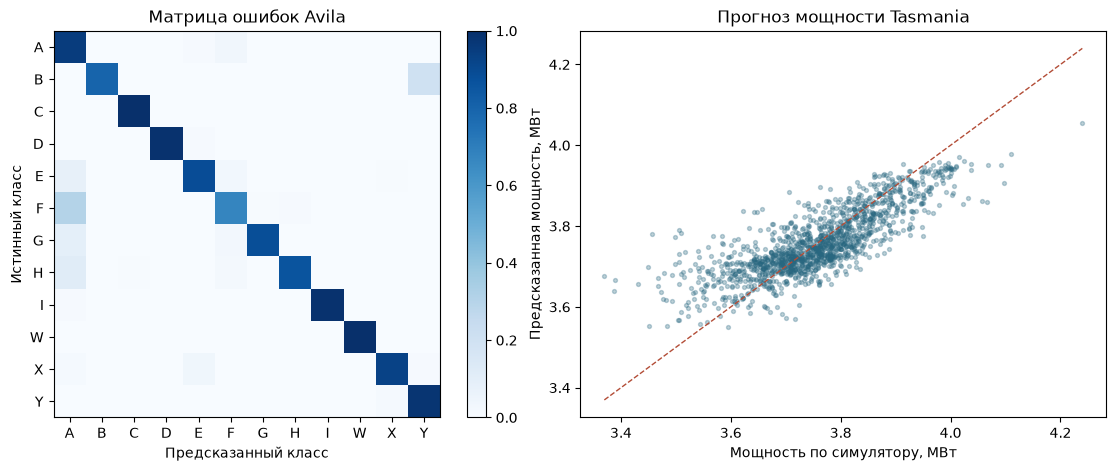

In [6]:
plot_predictions(tasks, results)

## Выводы

In [7]:
print(comparison_text(tasks, results, selections))
relative_path = save_scores(LAB, results)
print(f"Метрики сохранены в {relative_path.as_posix()}")

Avila (macro-F1)
По кросс-валидации выбран вариант «Глубина 4».
Среднее на фолдах: 0.7201 до настройки и 0.9106 после.
Sklearn на тесте: 0.7833 до настройки и 0.9290 после.
Своя модель на тесте: 0.7833 до настройки и 0.9316 после.
Разница со sklearn на тесте: +0.0000 до настройки и +0.0026 после.

Tasmania (MAE, МВт)
По кросс-валидации выбран вариант «Координаты и геометрия, глубина 3».
Среднее на фолдах: 0.0737 до настройки и 0.0517 после.
Sklearn на тесте: 0.0746 до настройки и 0.0501 после.
Своя модель на тесте: 0.0746 до настройки и 0.0501 после.
Разница со sklearn на тесте: +0.0000 до настройки и +0.0000 после.
Метрики сохранены в results/lab_05.csv
